In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (classification_report, roc_auc_score,
confusion_matrix, RocCurveDisplay,
average_precision_score)
import os
import warnings; warnings.filterwarnings('ignore')
print('Imports done')


Imports done


In [2]:
transactions = pd.read_csv('../data/processed/transactions.csv',
parse_dates=['invoice_date'])
features = pd.read_csv('../data/processed/customer_features.csv')
# Cutoff = 90 days before the last date in the data
cutoff = transactions['invoice_date'].max() - pd.Timedelta(days=90)
print('Last date in data:', transactions['invoice_date'].max().date())
print('Churn cutoff date:', cutoff.date())

Last date in data: 2011-12-09
Churn cutoff date: 2011-09-10


In [3]:
sales = transactions[transactions['is_cancellation']==False].copy()
# Data BEFORE cutoff → used to build features
before = sales[sales['invoice_date'] <= cutoff]
# Data AFTER cutoff → used to create the label
after = sales[sales['invoice_date'] > cutoff]
# Customers who were active before the cutoff
active_before = set(before['customer_id'].unique())
# Customers who bought AFTER the cutoff (not churned)
bought_after = set(after['customer_id'].unique())
# Label: 1 = churned (didn't buy after cutoff), 0 = retained
labels = pd.Series(
{cid: (0 if cid in bought_after else 1) for cid in active_before},
name='churned'
)
print('Churned :', labels.sum())
print('Retained :', (labels==0).sum())
print('Churn rate:', f'{labels.mean():.1%}')

Churned : 2976
Retained : 2289
Churn rate: 56.5%


In [4]:
# Recompute features using ONLY data before cutoff (no leakage!)
g = before.groupby('customer_id')
feat_before = pd.DataFrame({
'recency' : (cutoff - g['invoice_date'].max()).dt.days,
'frequency' : g['invoice'].nunique(),
'monetary' : g['line_revenue'].sum(),
'avg_order_value': g['line_revenue'].sum() / g['invoice'].nunique(),
'unique_products': g['stock_code'].nunique(),
}).reset_index()
# Keep only customers who were active before cutoff
feat_before = feat_before[feat_before['customer_id'].isin(active_before)]
feat_before = feat_before.set_index('customer_id')
# Align labels with features
y = labels.loc[feat_before.index]
X = feat_before
print('X shape:', X.shape)
print('y shape:', y.shape)
print('Null values:', X.isnull().sum().sum())

X shape: (5265, 5)
y shape: (5265,)
Null values: 0


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
X, y,
test_size = 0.2,
stratify = y, # maintains churn ratio in both sets
random_state= 42
)
print('Train size:', len(X_train))
print('Test size :', len(X_test))
print('Train churn rate:', f'{y_train.mean():.1%}')


Train size: 4212
Test size : 1053
Train churn rate: 56.5%


In [6]:
logreg = make_pipeline(
StandardScaler(),
LogisticRegression(class_weight='balanced',
max_iter=1000, random_state=42)
)
logreg.fit(X_train, y_train)
print('=== Logistic Regression ===')
print(classification_report(y_test, logreg.predict(X_test)))
print('ROC-AUC:', round(roc_auc_score(y_test, logreg.predict_proba(X_test)[:,1]),3))


=== Logistic Regression ===
              precision    recall  f1-score   support

           0       0.68      0.74      0.71       458
           1       0.78      0.73      0.76       595

    accuracy                           0.73      1053
   macro avg       0.73      0.73      0.73      1053
weighted avg       0.74      0.73      0.73      1053

ROC-AUC: 0.807


In [7]:
rf = RandomForestClassifier(
n_estimators = 300,
class_weight = 'balanced',
max_depth = None,
random_state = 42,
n_jobs = -1
)
rf.fit(X_train, y_train)
print('=== Random Forest ===')
print(classification_report(y_test, rf.predict(X_test)))
print('ROC-AUC:', round(roc_auc_score(y_test, rf.predict_proba(X_test)[:,1]),3))

=== Random Forest ===
              precision    recall  f1-score   support

           0       0.69      0.64      0.66       458
           1       0.74      0.78      0.76       595

    accuracy                           0.72      1053
   macro avg       0.71      0.71      0.71      1053
weighted avg       0.72      0.72      0.72      1053

ROC-AUC: 0.782


In [8]:
# Business-facing evaluation on the test set
# If marketing can only contact the riskiest 20% of customers, how many churners do we reach?
def top_k_capture(model, X_test, y_test, share=0.20):
    proba = model.predict_proba(X_test)[:, 1]
    y_true = np.array(y_test)
    k = int(share * len(proba))
    top = np.argsort(proba)[::-1][:k]
    return y_true[top].sum() / y_true.sum(), y_true[top].mean()

results = []
for name, model in [('Logistic Regression', logreg), ('Random Forest', rf)]:
    proba = model.predict_proba(X_test)[:, 1]
    capture, precision_top = top_k_capture(model, X_test, y_test)
    results.append({
        'model': name,
        'roc_auc': round(roc_auc_score(y_test, proba), 3),
        'pr_auc': round(average_precision_score(y_test, proba), 3),
        'top20_churner_capture': round(capture, 3),
        'top20_precision': round(precision_top, 3),
    })
results = pd.DataFrame(results).set_index('model')
results

,roc_auc,pr_auc,top20_churner_capture,top20_precision
model,,,,
Logistic Regression,0.807,0.836,0.316,0.895
Random Forest,0.782,0.799,0.304,0.862


## Model choice

Logistic Regression **outperforms** Random Forest on ROC-AUC and PR-AUC, so it is the final model.

Why the simpler model wins here:
- There are only 5 features, and churn is close to monotonic in each of them (the longer since the last purchase, the higher the risk). A linear model on standardised features captures that well.
- Random Forest with unlimited depth fits the training data closely and generalises slightly worse.
- Logistic Regression is also easier to explain to a marketing team: each coefficient says which direction a feature pushes churn risk.

Caveat: the train/test split is random (stratified), not out-of-time. The 90-day cutoff prevents leakage between features and labels, but a stricter test would score a later cohort.

In [9]:
# Drivers in the final model: standardised Logistic Regression coefficients
# Positive = pushes churn risk UP, negative = pushes it DOWN
lr_model = logreg.named_steps['logisticregression']
coefs = pd.Series(lr_model.coef_[0], index=X.columns).sort_values(key=abs, ascending=False)
print(coefs.round(3))

recency            0.789
frequency         -0.680
unique_products   -0.506
monetary          -0.017
avg_order_value   -0.001
dtype: float64


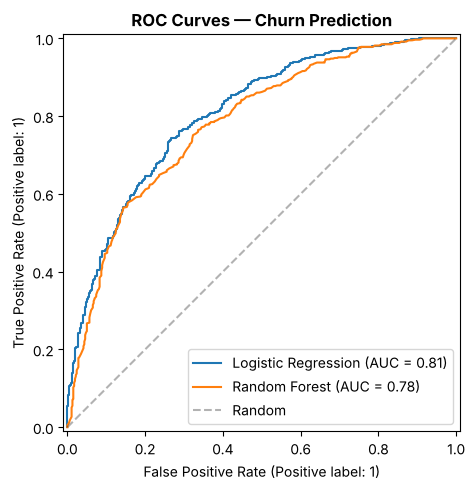

In [10]:
fig, ax = plt.subplots(figsize=(8,5))
RocCurveDisplay.from_estimator(logreg, X_test, y_test, ax=ax, name='Logistic Regression')
RocCurveDisplay.from_estimator(rf, X_test, y_test, ax=ax, name='Random Forest')
ax.set_title('ROC Curves — Churn Prediction', fontweight='bold')
ax.plot([0,1],[0,1],'k--', alpha=0.3, label='Random')
ax.legend()
plt.tight_layout()
plt.savefig('../reports/figures/07_roc_curves.png', bbox_inches='tight')
plt.show()

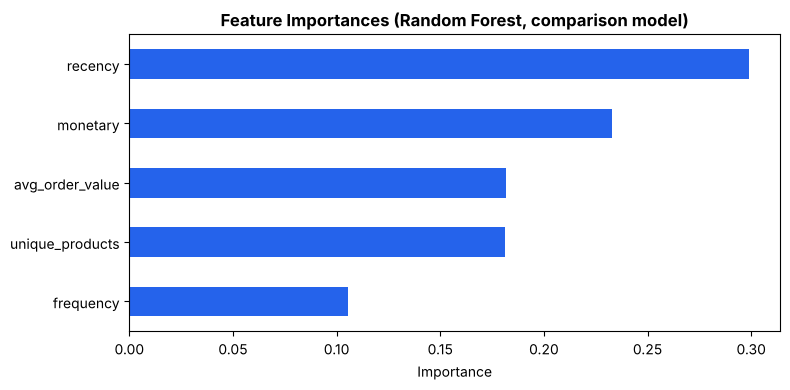

recency            0.298938
monetary           0.233048
avg_order_value    0.181482
unique_products    0.181110
frequency          0.105422
dtype: float64


In [11]:
# Random Forest feature importance (for comparison with the LR coefficients above)
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8,4))
imp.head(10).sort_values().plot.barh(ax=ax, color='#2563EB')
ax.set_title('Feature Importances (Random Forest, comparison model)', fontweight='bold')
ax.set_xlabel('Importance')
plt.tight_layout()
plt.savefig('../reports/figures/08_feature_importance.png', bbox_inches='tight')
plt.show()
print(imp.head(10))

In [12]:
# Score ALL customers (use full features, not just the train/test split)
X_all = feat_before
final_model = logreg   # chosen model, see 'Model choice' above
churn_proba = final_model.predict_proba(X_all)[:,1]
churn_scores = pd.DataFrame({
'customer_id' : X_all.index,
'churn_probability' : churn_proba
})
churn_scores['risk_band'] = pd.cut(
churn_scores['churn_probability'],
bins=[0, 0.4, 0.7, 1.0],
labels=['Low', 'Medium', 'High']
)
churn_scores.to_csv('../data/processed/churn_scores.csv', index=False)
print('Churn scores exported')
print(churn_scores['risk_band'].value_counts())

Churn scores exported
risk_band
Medium    1987
Low       1754
High      1524
Name: count, dtype: int64


In [13]:
import pickle
os.makedirs('../models', exist_ok=True)
with open('../models/churn_model_logreg.pkl', 'wb') as f:
    pickle.dump(logreg, f)
print('Model saved to models/churn_model_logreg.pkl')

Model saved to models/churn_model_logreg.pkl
